# code_115 · Prediction units and relational baselines

**Book:** section 23.1. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_23_GUIDE.md), [run evidence](../CHAPTER_23_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_115).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2515;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2515


<a id="graph-task-contract"></a>
 ## One topology, distinct targets
 Generate sixty independent building graphs with 10–16 member nodes, a connected ring and additional undirected connections. Loads/material/capacity are observed inputs; damage labels and connection failures are later independent Bernoulli outcomes from declared probabilities. Training/development/final graphs are 40/10/10. Predict damage on nodes and failure on existing connections; neither task predicts whether an absent connection exists. A whole-building damaged-fraction readout averages node probabilities and is assessed against the observed fraction; it is not separately trained as a graph classifier. All final graphs are unseen during fitting. Compare own-feature logistic regression, a non-neural neighborhood-aggregate logistic baseline, and a genuine two-layer mean-aggregation graph encoder with node and symmetric edge heads. Only the neural candidate searches two rates; capacities and fitting budgets differ.


,task,method,development_Brier,final_Brier
0,Member damage,Own features,0.206207,0.214864
1,Member damage,Relational logistic,0.165768,0.162630
2,Connection failure,Endpoint logistic,0.166275,0.168729
3,Member damage,Graph encoder,0.173402,0.151054
4,Connection failure,Graph encoder,0.160565,0.185988


,method,final_fraction_MSE
0,Own features,0.048037
1,Relational logistic,0.023010
2,Graph encoder,0.020211


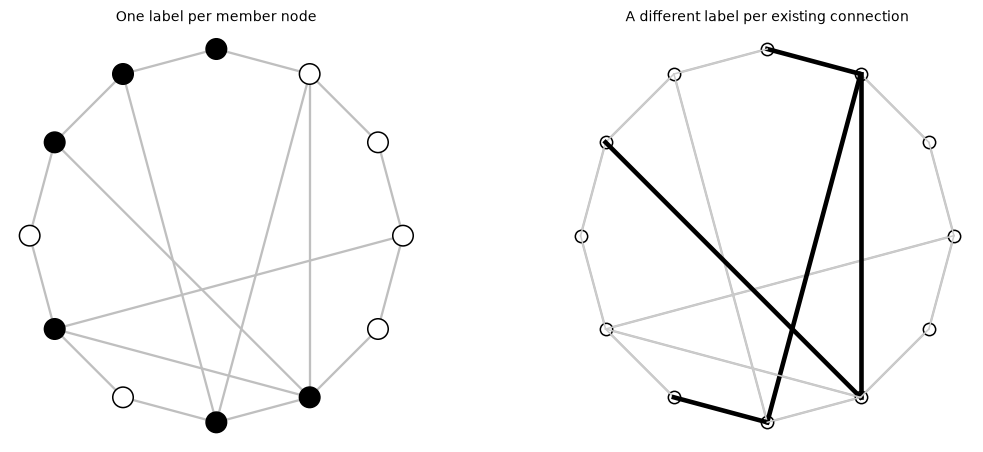

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
def sigmoid(v):return 1/(1+np.exp(-v))
graphs=[];offset=0
for building in range(60):
    n=int(rng.integers(10,17));raw=rng.normal(size=(n,3));pairs={(i,(i+1)%n) if i<(i+1)%n else ((i+1)%n,i) for i in range(n)}
    pairs|={(i,j) for i in range(n) for j in range(i+1,n) if rng.random()<.08};pairs=np.array(sorted(pairs),dtype=int);a=np.zeros((n,n));a[pairs[:,0],pairs[:,1]]=1;a+=a.T;mean=a@raw/a.sum(1)[:,None]
    node_p=sigmoid(.9*raw[:,0]+1.5*mean[:,0]-.5*raw[:,1]);node_y=rng.binomial(1,node_p).astype(float);capacity=rng.uniform(.4,1.8,len(pairs));u,v=pairs.T;edge_p=sigmoid(1.3*np.abs(raw[u,0]-raw[v,0])-1.2*capacity-.8);edge_y=rng.binomial(1,edge_p).astype(float)
    graphs.append(dict(n=n,raw=raw,pairs=pairs,a=a,node_y=node_y,edge_y=edge_y,capacity=capacity,offset=offset));offset+=n
raw=np.concatenate([g['raw'] for g in graphs]);node_building=np.concatenate([np.full(g['n'],i) for i,g in enumerate(graphs)]);node_y=np.concatenate([g['node_y'] for g in graphs]);scaler=StandardScaler().fit(raw[node_building<40]);x=torch.tensor(scaler.transform(raw));edge_u=np.concatenate([g['pairs'][:,0]+g['offset'] for g in graphs]);edge_v=np.concatenate([g['pairs'][:,1]+g['offset'] for g in graphs]);edge_building=np.concatenate([np.full(len(g['pairs']),i) for i,g in enumerate(graphs)]);edge_y=np.concatenate([g['edge_y'] for g in graphs]);capacity=np.concatenate([g['capacity'] for g in graphs]);src=torch.tensor(np.r_[edge_u,edge_v]);dst=torch.tensor(np.r_[edge_v,edge_u]);degree=torch.bincount(dst,minlength=len(x)).to(x.dtype)
def aggregate(h):
    total=torch.zeros_like(h);total.index_add_(0,dst,h[src]);return total/degree[:,None]
assert torch.all(degree>0) and np.all(node_building[src.numpy()]==node_building[dst.numpy()])
aggregate_x=aggregate(x).numpy();node_features={'Own features':x.numpy(),'Relational logistic':np.c_[x.numpy(),aggregate_x]};edge_features=np.c_[x.numpy()[edge_u]+x.numpy()[edge_v],np.abs(x.numpy()[edge_u]-x.numpy()[edge_v]),capacity];rows=[];predictions={}
nt=node_building<40;nd=(node_building>=40)&(node_building<50);nf=node_building>=50;et=edge_building<40;ed=(edge_building>=40)&(edge_building<50);ef=edge_building>=50
for name,features in node_features.items():
    model=LogisticRegression(C=1,max_iter=1000).fit(features[nt],node_y[nt]);p=model.predict_proba(features)[:,1];predictions[name]=p;rows.append({'task':'Member damage','method':name,'development_Brier':float(np.mean((p[nd]-node_y[nd])**2)),'final_Brier':float(np.mean((p[nf]-node_y[nf])**2))})
model=LogisticRegression(C=1,max_iter=1000).fit(edge_features[et],edge_y[et]);edge_logistic=model.predict_proba(edge_features)[:,1];rows.append({'task':'Connection failure','method':'Endpoint logistic','development_Brier':float(np.mean((edge_logistic[ed]-edge_y[ed])**2)),'final_Brier':float(np.mean((edge_logistic[ef]-edge_y[ef])**2))})
class GraphTasks(nn.Module):
    def __init__(self):
        super().__init__();self.own1=nn.Linear(3,12);self.neighbor1=nn.Linear(3,12,bias=False);self.own2=nn.Linear(12,12);self.neighbor2=nn.Linear(12,12,bias=False);self.node=nn.Linear(12,1);self.edge=nn.Sequential(nn.Linear(25,12),nn.ReLU(),nn.Linear(12,1))
    def forward(self,features):
        h=torch.relu(self.own1(features)+self.neighbor1(aggregate(features)));h=torch.relu(self.own2(h)+self.neighbor2(aggregate(h)));pair=torch.cat([h[edge_u]+h[edge_v],torch.abs(h[edge_u]-h[edge_v]),torch.tensor(capacity)[:,None]],dim=1);return self.node(h).ravel(),self.edge(pair).ravel()
ty=torch.tensor(node_y);ey=torch.tensor(edge_y);candidates=[]
for rate in [.005,.01]:
    torch.manual_seed(SEED);model=GraphTasks();opt=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=np.inf
    for step in range(1,251):
        opt.zero_grad();pn,pe=model(x);loss=nn.functional.binary_cross_entropy_with_logits(pn[nt],ty[nt])+nn.functional.binary_cross_entropy_with_logits(pe[et],ey[et]);loss.backward();opt.step()
        if step%10==0:
            with torch.no_grad():pn,pe=model(x);score=float(torch.mean((pn[nd].sigmoid()-ty[nd])**2)+torch.mean((pe[ed].sigmoid()-ey[ed])**2))
            if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
    candidates.append({'rate':rate,'development_sum_Brier':best,'best_step':best_step,'state':state})
selected=min(candidates,key=lambda r:r['development_sum_Brier']);model.load_state_dict(selected['state']);model.eval()
with torch.no_grad():pn,pe=model(x);pn=pn.sigmoid().numpy();pe=pe.sigmoid().numpy()
predictions['Graph encoder']=pn
for task,p,target,dev,final in [('Member damage',pn,node_y,nd,nf),('Connection failure',pe,edge_y,ed,ef)]:rows.append({'task':task,'method':'Graph encoder','development_Brier':float(np.mean((p[dev]-target[dev])**2)),'final_Brier':float(np.mean((p[final]-target[final])**2))})
graph_readout=[]
for name,p in predictions.items():
    values=[(float(p[node_building==i].mean()),float(node_y[node_building==i].mean())) for i in range(50,60)];graph_readout.append({'method':name,'final_fraction_MSE':float(np.mean([(a-b)**2 for a,b in values]))})
assert sum(g['n'] for g in graphs)==len(x) and len(pe)==len(edge_u) and np.isfinite(pn).all()
# Symmetric edge features make arbitrary endpoint ordering irrelevant.
torch.testing.assert_close(torch.abs(x[edge_u]-x[edge_v]),torch.abs(x[edge_v]-x[edge_u]))
RESULTS.update(comparisons=rows,graph_readout=graph_readout,split_buildings=[40,10,10],node_counts=[g['n'] for g in graphs],final_nodes=int(nf.sum()),final_connections=int(ef.sum()),stored_graph_parameters=sum(p.numel() for p in model.parameters()),selected_rate=selected['rate'],selected_step=selected['best_step'],neural_candidates=[{k:v for k,v in r.items() if k!='state'} for r in candidates]);display(pd.DataFrame(rows));display(pd.DataFrame(graph_readout))
g=graphs[50];theta=np.linspace(0,2*np.pi,g['n'],endpoint=False);pos=np.c_[np.cos(theta),np.sin(theta)];fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax in axes:
    for u,v in g['pairs']:ax.plot(*pos[[u,v]].T,color='.75',zorder=0)
    ax.set_aspect('equal');ax.axis('off')
axes[0].scatter(*pos.T,c=g['node_y'],cmap='Greys',vmin=0,vmax=1,s=180,edgecolors='black');axes[0].set_title('One label per member node')
for (u,v),value in zip(g['pairs'],g['edge_y']):axes[1].plot(*pos[[u,v]].T,color='black' if value else '.8',linewidth=3 if value else 1)
axes[1].scatter(*pos.T,c='white',s=65,edgecolors='black');axes[1].set_title('A different label per existing connection');plt.show()


<a id="prediction-unit-limits"></a>
 ## Aggregation already supplies relational information
 Whole-building splitting keeps connected outcomes together. Every node's inputs and known topology inside its own final building are available at prediction, but no label is used by message passing. This is inductive assessment on unseen graphs, not a random node split over one transductive graph. The logistic relational baseline already receives graph-derived covariates, so a graph encoder must earn an improvement over it. Edge failure labels describe existing connections; link prediction additionally requires a candidate-pair universe and negative/censoring policy. Averaging node probabilities gives an expected damaged fraction under marginal predictions without claiming independent outcomes or a calibrated interval for that fraction.


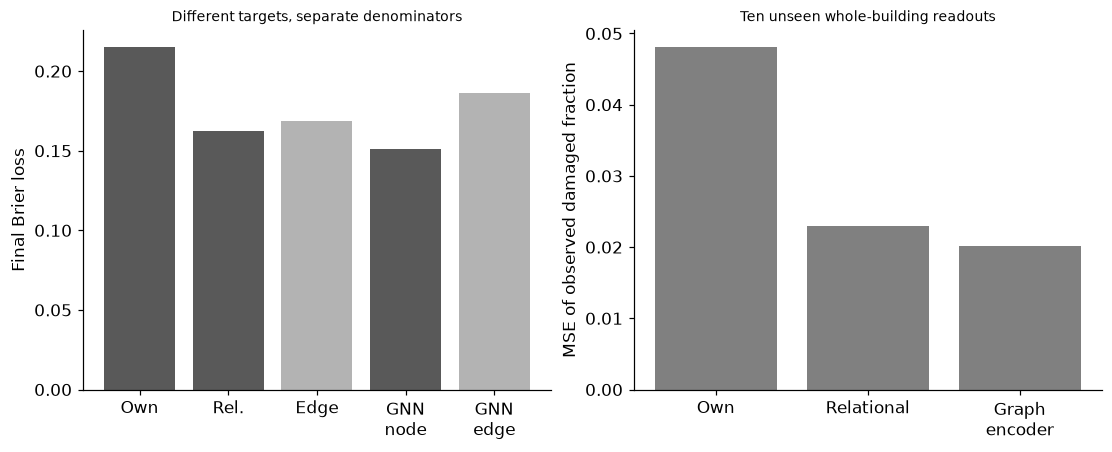

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for index,row in enumerate(rows):axes[0].bar(index,row['final_Brier'],color='.35' if row['task']=='Member damage' else '.7')
axes[0].set(xticks=range(len(rows)),xticklabels=['Own','Rel.','Edge','GNN\nnode','GNN\nedge'],ylabel='Final Brier loss',title='Different targets, separate denominators')
axes[1].bar(range(3),[r['final_fraction_MSE'] for r in graph_readout],color='.5');axes[1].set(xticks=range(3),xticklabels=['Own','Relational','Graph\nencoder'],ylabel='MSE of observed damaged fraction',title='Ten unseen whole-building readouts');plt.show()
assert all(0<=r['final_Brier']<=1 for r in rows)


In [4]:
summary={'example_id':'code_115','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['node versus existing-edge targets', 'non-neural aggregated baseline', 'actual shared graph encoder and task heads', 'whole-building holdout', 'whole-graph mean readout'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["node versus existing-edge targets", "non-neural aggregated baseline", "actual shared graph encoder and task heads", "whole-building holdout", "whole-graph mean readout"], "elapsed_seconds": 1.728, "example_id": "code_115", "hardware": "Darwin arm64 CPU", "results": {"comparisons": [{"development_Brier": 0.20620721688841698, "final_Brier": 0.21486413177777014, "method": "Own features", "task": "Member damage"}, {"development_Brier": 0.16576784864980104, "final_Brier": 0.16263038000942462, "method": "Relational logistic", "task": "Member damage"}, {"development_Brier": 0.1662751325373752, "final_Brier": 0.168729006822111, "method": "Endpoint logistic", "task": "Connection failure"}, {"development_Brier": 0.17340247857830987, "final_Brier": 0.15105377004342088, "method": "Graph encoder", "task": "Member damage"}, {"development_Brier": 0.16056497191901492, "final_Brier": 0.18598812941230758, "method": "Graph encoder", "task": "Connection f